<a href="https://colab.research.google.com/github/AkshatBajpai4218/Cardiac-Pacemaker/blob/main/Smart_Pacemaker_AI_IoT_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Pacemaker: AI + IoT Prototype (Google Colab)
**Project:** Enhancing Cardiac Health with an AI & IoT-Embedded Pacemaker, a design-thinking approach.

**Persona:** Rajesh Verma, 65, arrhythmia and hypertension, not tech-savvy. He needs *a smart, safe, and simple pacemaker*.

This notebook turns the deck's recommendations into a runnable simulation. Run all cells top to bottom (**Runtime > Run all**). No installs or uploads are needed.

| Deck recommendation | Notebook section |
|---|---|
| Real-time monitoring | 1-2: simulated ECG stream + R-peak detection |
| Predictive AI alerts | 3-4: rhythm classifier + 24h early-warning simulation |
| Alerts to family and doctors | 5: escalation logic |
| Wireless charging / battery management | 6: battery and charging simulation |
| Secure app interface | 7: signed messages + role-based access |
| Simple interface | 8: one-screen patient summary |

> **Disclaimer:** all data is synthetic. This is an educational prototype, not a medical device, and must not be used for diagnosis or treatment.

**Team:** edit the `CONFIG` cell and the TODO markers; each section maps to a workstream.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

CONFIG = dict(
    fs=125,               # ECG sampling rate (Hz)
    window_s=30,          # analysis window length (s)
    alert_threshold=0.6,  # risk above this (smoothed) raises an alert
    smooth_windows=5,     # median filter length for risk score
    seed=42,
)
rng = np.random.default_rng(CONFIG['seed'])
CLASSES = ['Normal', 'Tachycardia', 'Bradycardia', 'Irregular (AF-like)']
print('Setup OK')

Setup OK


## 1. Simulated ECG stream (IoT sensor)
A synthetic ECG is built from P, QRS and T waves placed at each heartbeat, plus noise and baseline drift. Each rhythm class has its own heart rate and beat-to-beat variability.

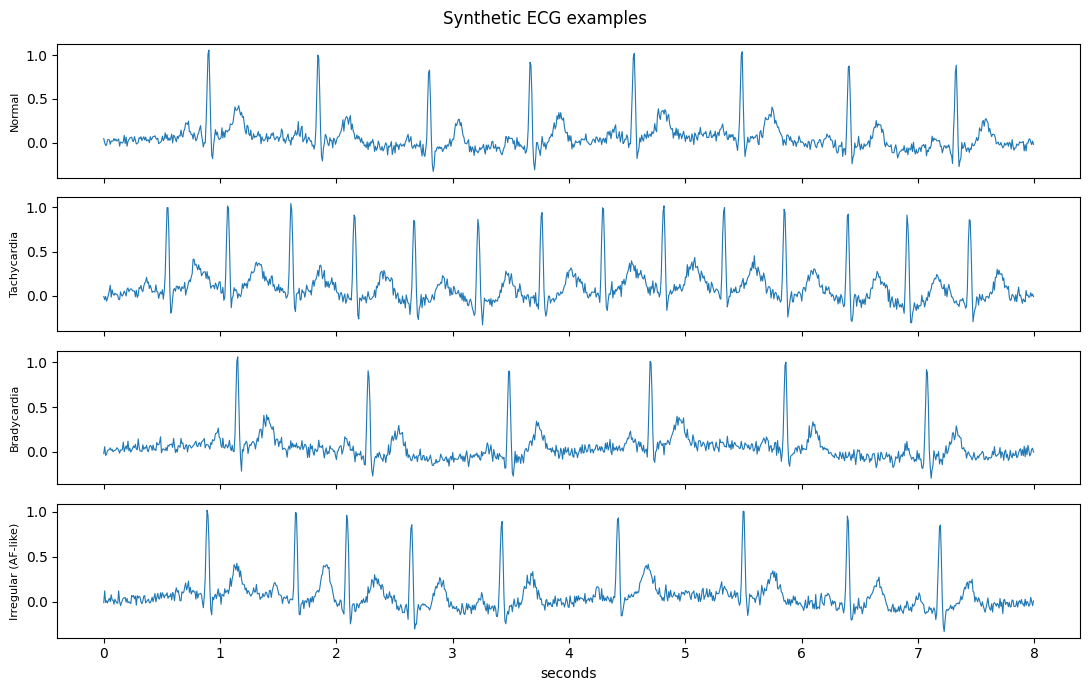

In [2]:
def beat_template(fs):
    t = np.arange(-0.3, 0.5, 1/fs)
    g = lambda mu, sd, a: a*np.exp(-0.5*((t-mu)/sd)**2)
    return g(-0.18,0.025,0.12)+g(-0.03,0.010,-0.12)+g(0.0,0.012,1.0)+g(0.03,0.010,-0.25)+g(0.25,0.045,0.30)
TEMPLATE = beat_template(CONFIG['fs'])

def rr_intervals(kind, dur, irregularity=None):
    # returns beat-to-beat intervals (s) covering `dur` seconds
    n = int(dur*3)+10
    if kind == 'Normal':       base, var = rng.uniform(0.67,1.0), 0.03
    elif kind == 'Tachycardia': base, var = rng.uniform(0.40,0.55), 0.03
    elif kind == 'Bradycardia': base, var = rng.uniform(1.20,1.70), 0.04
    else:                       base, var = rng.uniform(0.55,0.9), 0.30   # irregular
    if irregularity is not None:   # graded: 0 = normal-like, 1 = fully irregular
        base, var = rng.uniform(0.67,0.9), 0.03 + 0.27*irregularity
    rr = base*(1 + var*rng.standard_normal(n))
    return np.clip(rr, 0.25, 2.5)

def make_ecg(kind, dur=None, irregularity=None):
    fs = CONFIG['fs']; dur = dur or CONFIG['window_s']
    x = np.zeros(int(dur*fs))
    beats = np.cumsum(rr_intervals(kind, dur, irregularity))
    beats = beats[beats < dur-0.5]
    for b in beats:
        i = int(b*fs) - int(0.3*fs)
        lo, hi = max(i,0), min(i+len(TEMPLATE), len(x))
        x[lo:hi] += TEMPLATE[lo-i:hi-i]
    t = np.arange(len(x))/fs
    x += 0.08*np.sin(2*np.pi*0.25*t) + 0.04*rng.standard_normal(len(x))   # drift + noise
    return x

fig, ax = plt.subplots(4,1, figsize=(11,7), sharex=True)
for a,k in zip(ax, CLASSES):
    kk = 'Irregular' if k.startswith('Irreg') else k
    sig = make_ecg(kk, dur=8); a.plot(np.arange(len(sig))/CONFIG['fs'], sig, lw=.8); a.set_ylabel(k, fontsize=8)
ax[-1].set_xlabel('seconds'); fig.suptitle('Synthetic ECG examples'); plt.tight_layout(); plt.show()

## 2. On-device signal processing: R-peak detection and HRV features
The chip detects heartbeats and computes heart-rate variability (HRV) features, small enough for an ultra-low-power processor.

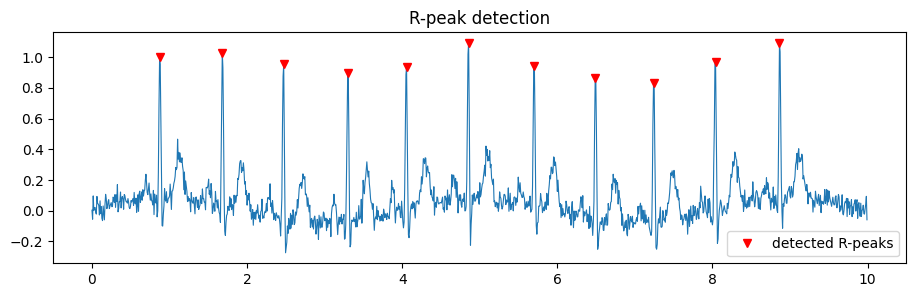

{'mean_HR_bpm': 75.08, 'SDNN_ms': 27.12, 'RMSSD_ms': 44.14, 'pNN50': 0.11, 'CV': 0.03, 'n_beats': 11.0}


In [3]:
def extract_features(sig):
    fs = CONFIG['fs']
    peaks,_ = find_peaks(sig, height=0.55*np.max(sig), distance=int(0.25*fs))
    rr = np.diff(peaks)/fs
    if len(rr) < 3: return np.zeros(6)
    d = np.diff(rr)
    return np.array([60/rr.mean(), rr.std()*1000, np.sqrt(np.mean(d**2))*1000,
                     np.mean(np.abs(d) > 0.05), rr.std()/rr.mean(), len(peaks)])
FEATURES = ['mean_HR_bpm','SDNN_ms','RMSSD_ms','pNN50','CV','n_beats']

sig = make_ecg('Normal', dur=10)
pk,_ = find_peaks(sig, height=0.55*sig.max(), distance=int(0.25*CONFIG['fs']))
plt.figure(figsize=(11,3)); plt.plot(np.arange(len(sig))/CONFIG['fs'], sig, lw=.8)
plt.plot(pk/CONFIG['fs'], sig[pk], 'rv', label='detected R-peaks'); plt.legend(); plt.title('R-peak detection'); plt.show()
print(dict(zip(FEATURES, extract_features(sig).round(2).tolist())))

## 3. AI rhythm classifier
A Random Forest (light enough to port to a microcontroller) learns to tell the four rhythms apart from HRV features. Irregular training samples include *graded* irregularity so the model also notices early warning signs.

Note: ~100% accuracy is expected because synthetic rhythms are easy to separate. Real data (TODO below) will be much harder.
                     precision    recall  f1-score   support

             Normal       1.00      1.00      1.00        75
        Tachycardia       1.00      1.00      1.00        75
        Bradycardia       1.00      1.00      1.00        75
Irregular (AF-like)       1.00      1.00      1.00        75

           accuracy                           1.00       300
          macro avg       1.00      1.00      1.00       300
       weighted avg       1.00      1.00      1.00       300



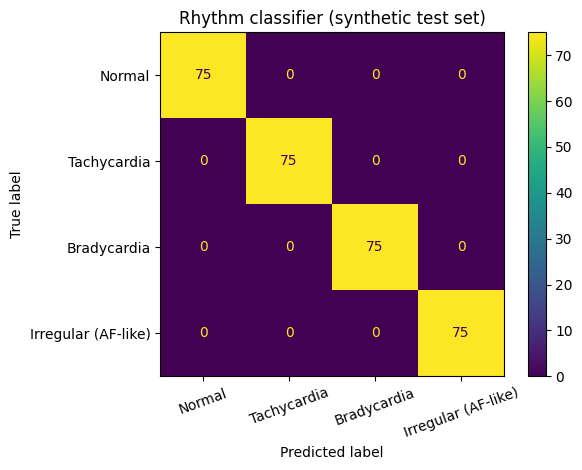

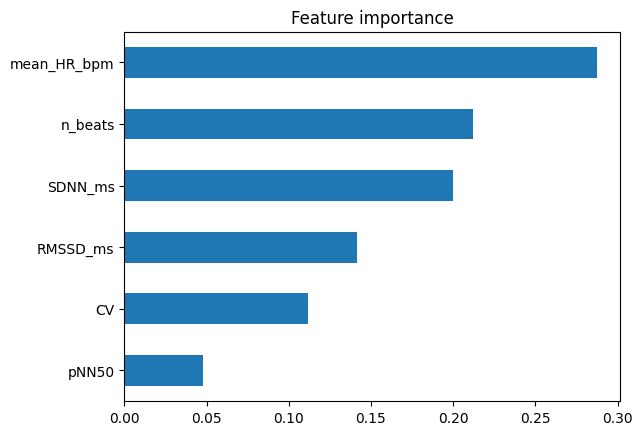

In [4]:
X, y = [], []
N = 300
for label,k in enumerate(['Normal','Tachycardia','Bradycardia']):
    for _ in range(N):
        X.append(extract_features(make_ecg(k))); y.append(label)
for _ in range(N):
    X.append(extract_features(make_ecg('Irregular', irregularity=rng.uniform(0.5,1.0)))); y.append(3)
X, y = np.array(X), np.array(y)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=CONFIG['seed'])
clf = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=CONFIG['seed']).fit(Xtr, ytr)
pred = clf.predict(Xte)
print('Note: ~100% accuracy is expected because synthetic rhythms are easy to separate. Real data (TODO below) will be much harder.')
print(classification_report(yte, pred, target_names=CLASSES))
ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=CLASSES, xticks_rotation=20)
plt.title('Rhythm classifier (synthetic test set)'); plt.tight_layout(); plt.show()
pd.Series(clf.feature_importances_, index=FEATURES).sort_values().plot.barh(title='Feature importance'); plt.show()

## 4. Predictive alerts: 24-hour early-warning simulation
We simulate one day of Rajesh's heart: mostly normal, then **irregularity slowly builds from 15:00** and a full episode starts at **16:00**. The system computes a risk score (probability the rhythm is *not* normal) every few minutes, smooths it, and raises an alert when it crosses the threshold, ideally *before* the full episode.

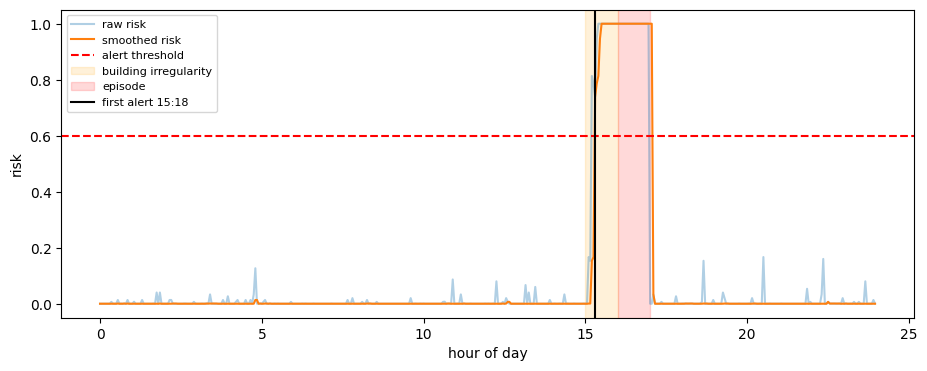

First alert: 15:18 | episode onset: 16:00
Lead time before full episode (min): 42
False alerts during normal hours (windows): 0


In [5]:
STEP_MIN = 3                                   # one 30 s window every 3 minutes
minutes = np.arange(0, 24*60, STEP_MIN)
level = np.zeros(len(minutes))                 # true irregularity level
ramp = (minutes >= 15*60) & (minutes < 16*60)
level[ramp] = (minutes[ramp]-15*60)/60
level[(minutes >= 16*60) & (minutes < 17*60)] = 1.0     # episode
risk = []
for lv in level:
    kind = 'Normal'
    sig = make_ecg(kind) if lv == 0 else make_ecg('Irregular', irregularity=lv)
    p = clf.predict_proba([extract_features(sig)])[0]
    risk.append(1 - p[0])
risk = np.array(risk)
smooth = pd.Series(risk).rolling(CONFIG['smooth_windows'], center=False, min_periods=1).median().values
alert_idx = np.where(smooth > CONFIG['alert_threshold'])[0]
first_alert = minutes[alert_idx[0]] if len(alert_idx) else None
fmt = lambda m: f'{int(m//60):02d}:{int(m%60):02d}'
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(minutes/60, risk, alpha=.35, label='raw risk'); ax.plot(minutes/60, smooth, label='smoothed risk')
ax.axhline(CONFIG['alert_threshold'], color='r', ls='--', label='alert threshold')
ax.axvspan(15,16,color='orange',alpha=.15,label='building irregularity'); ax.axvspan(16,17,color='red',alpha=.15,label='episode')
if first_alert is not None: ax.axvline(first_alert/60, color='k', label=f'first alert {fmt(first_alert)}')
ax.set_xlabel('hour of day'); ax.set_ylabel('risk'); ax.legend(loc='upper left', fontsize=8); plt.show()
false = int(np.sum(smooth[minutes < 15*60] > CONFIG['alert_threshold']))
print('First alert:', fmt(first_alert) if first_alert is not None else 'none', '| episode onset: 16:00')
if first_alert is not None: print('Lead time before full episode (min):', 16*60 - first_alert)
print('False alerts during normal hours (windows):', false)

## 5. Emergency escalation to family and doctor
Alerts are staged so Rajesh is never overwhelmed or alarmed needlessly: a gentle nudge first, then family, then the doctor. Messages here are printed; in a real system they would go through push, SMS or call services.

**TODO (team):** tune the times and thresholds with a clinical advisor.

In [6]:
ESCALATION = [  # (risk level, who is told, message)
    (0.60, 'Patient (app)',  'Your heart rhythm looks a little unusual. Please sit down and rest.'),
    (0.80, 'Family contact', 'Rajesh\'s heart rhythm is unusual. Please call him.'),
    (0.92, 'Doctor + ambulance prompt', 'High-risk rhythm detected. Review live data now.'),
]
def escalate(t_min, score, sent):
    for lvl, who, msg in ESCALATION:
        if score >= lvl and who not in sent:
            sent[who] = t_min; print(f'[{fmt(t_min)}] -> {who}: {msg} (risk {score:.2f})')
sent = {}
for tm, s in zip(minutes, smooth): escalate(tm, s, sent)

[15:18] -> Patient (app): Your heart rhythm looks a little unusual. Please sit down and rest. (risk 0.74)
[15:24] -> Family contact: Rajesh's heart rhythm is unusual. Please call him. (risk 0.81)
[15:27] -> Doctor + ambulance prompt: High-risk rhythm detected. Review live data now. (risk 0.95)


## 6. Power and maintenance: battery and wireless charging
The deck proposes ultra-low-power AI chips and low-frequency inductive charging so the device never needs replacement surgery. This simulates 30 days of battery level with a nightly charging pad and a low-battery (below 50%) reminder.

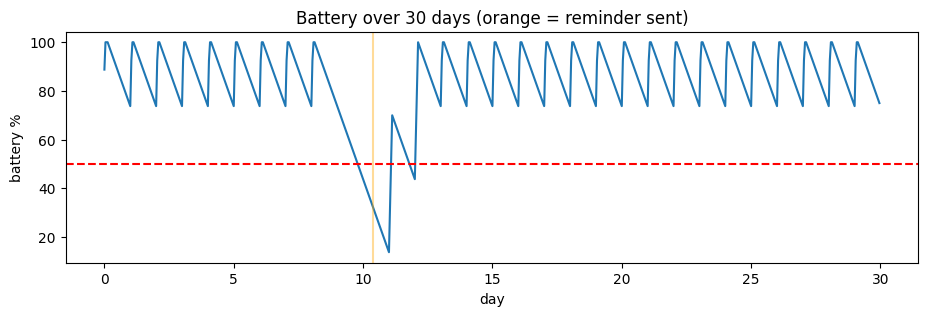

Lowest level: 13.8% | reminders sent: 1


In [7]:
days = 30; hours = np.arange(days*24)
cap_mAh = 200; draw_mA = 2.5          # average drain with ultra-low-power AI chip (assumed)
charge_mA = 40                          # inductive charger rate (assumed)
batt = np.zeros(len(hours)); level_mAh = cap_mAh*0.9; notices = []
for i,h in enumerate(hours):
    hod = h % 24
    on_pad = (hod in (1,2,3)) and not (h//24 in (9,10))     # patient forgets the charger for 2 nights
    level_mAh += (charge_mA if on_pad else 0) - draw_mA*1.0
    level_mAh = min(max(level_mAh, 0), cap_mAh)
    batt[i] = 100*level_mAh/cap_mAh
    if batt[i] < 50 and hod == 9: notices.append(h)
plt.figure(figsize=(11,3)); plt.plot(hours/24, batt); plt.axhline(50,color='r',ls='--')
for n in notices: plt.axvline(n/24, color='orange', alpha=.4)
plt.xlabel('day'); plt.ylabel('battery %'); plt.title('Battery over 30 days (orange = reminder sent)'); plt.show()
print('Lowest level: %.1f%%' % batt.min(), '| reminders sent:', len(notices))

## 7. Secure interface: signed messages and role-based access
Patient data is pseudonymized, every message is signed so tampering is detectable, and each role sees only what it needs. (This demonstrates the idea; a real device needs vetted encryption and regulatory review.)

In [8]:
import hmac, hashlib, json, time
SECRET = b'demo-key-change-me'           # in production: per-device key in secure hardware
def pseudonym(pid): return hashlib.sha256(b'salt'+pid.encode()).hexdigest()[:10]
def sign(payload):
    body = json.dumps(payload, sort_keys=True).encode()
    return {'body': payload, 'sig': hmac.new(SECRET, body, hashlib.sha256).hexdigest()}
def verify(msg):
    body = json.dumps(msg['body'], sort_keys=True).encode()
    return hmac.compare_digest(msg['sig'], hmac.new(SECRET, body, hashlib.sha256).hexdigest())
ACCESS = {'patient': {'status','alerts'}, 'family': {'status','alerts'},
          'doctor': {'status','alerts','ecg','hrv','history'}}
def view(role, record): return {k:v for k,v in record.items() if k in ACCESS[role]}

record = {'patient': pseudonym('rajesh-lucknow-001'), 'status': 'Alert: unusual rhythm', 'alerts': len(sent),
          'ecg': 'raw waveform ...', 'hrv': dict(zip(FEATURES, extract_features(make_ecg('Normal')).round(1).tolist())), 'history': '24h'}
msg = sign(record); print('Signature valid:', verify(msg))
msg['body']['alerts'] = 0; print('After tampering valid:', verify(msg))
for role in ACCESS: print(role.upper(), '->', list(view(role, record).keys()))

Signature valid: True
After tampering valid: False
PATIENT -> ['status', 'alerts']
FAMILY -> ['status', 'alerts']
DOCTOR -> ['status', 'alerts', 'ecg', 'hrv', 'history']


## 8. Simple one-screen summary for Rajesh
The persona wants something that *quietly protects him without needing to be a tech expert*. The patient view is one colour, one sentence, one action.

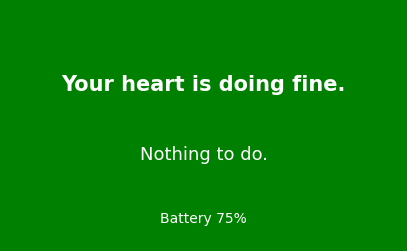

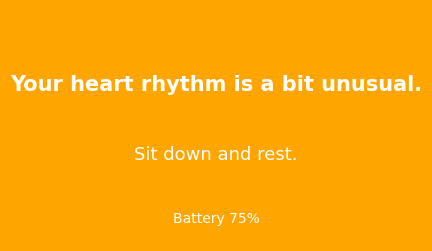

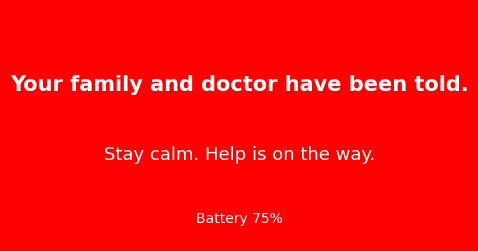

In [9]:
def patient_screen(score, battery):
    if score < CONFIG['alert_threshold']: color, text, action = 'green', 'Your heart is doing fine.', 'Nothing to do.'
    elif score < 0.8: color, text, action = 'orange', 'Your heart rhythm is a bit unusual.', 'Sit down and rest.'
    else: color, text, action = 'red', 'Your family and doctor have been told.', 'Stay calm. Help is on the way.'
    fig, ax = plt.subplots(figsize=(5,3)); ax.set_facecolor(color); fig.patch.set_facecolor(color)
    ax.text(.5,.65,text,ha='center',fontsize=15,color='white',weight='bold',wrap=True)
    ax.text(.5,.35,action,ha='center',fontsize=13,color='white')
    ax.text(.5,.08,f'Battery {battery:.0f}%',ha='center',fontsize=10,color='white'); ax.axis('off'); plt.show()
for s in (0.1, 0.7, 0.95): patient_screen(s, batt[-1])

## 9. Next steps for the team
- [ ] Replace synthetic ECG with a public dataset (e.g. MIT-BIH Arrhythmia Database on PhysioNet) and re-evaluate.
- [ ] Add a sequence model to predict events *minutes ahead*, not just detect them.
- [ ] Calibrate alert thresholds and false-alarm rate with a clinical advisor.
- [ ] Run usability tests of the screens in section 8 with elderly users.
- [ ] Replace demo security with proper encryption and a privacy review.

*Based on the deck "Enhancing Cardiac Health with AI & IoT-Embedded Pacemaker".*